**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5061.10 - Operaciones de aprendizaje automático (Gpo 10)**

Tecnológico de Monterrey

---

# Actividad | Dataset - Notebook | Individual

**Curso:** TC5061  
**Estudiante:** Daniel Ruán Aguilar  
**Matrícula:** A01731921  
**Dataset:** Breast Cancer Wisconsin (Diagnostic)  
**Tipo de problema:** Clasificación binaria  
**Modelo base:** Regresión logística  

## Objetivo

El propósito de este notebook es recorrer de manera reproducible el flujo básico de un proyecto de Machine Learning. Se carga y describe un conjunto de datos, se realiza un análisis exploratorio, se revisan y tratan problemas de calidad, se entrena un modelo base de clasificación y se evalúa su desempeño en datos no utilizados durante el entrenamiento.

In [1]:
import sys
print(sys.executable)
print(sys.version)

C:\Program Files\Python314\python.exe
3.14.0 (tags/v3.14.0:ebf955d, Oct  7 2025, 10:15:03) [MSC v.1944 64 bit (AMD64)]


In [2]:
# Manipulación y visualización de datos
import sys
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preparación, entrenamiento y evaluación
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Configuración reproducible
RANDOM_STATE = 42
TEST_SIZE = 0.20
TARGET_COLUMN = "diagnosis"
ID_COLUMN = "id"

pd.set_option("display.max_columns", None)

print("Python:", sys.version.split()[0])
print("Sistema operativo:", platform.platform())
print("Pandas:", pd.__version__)

Python: 3.14.0
Sistema operativo: Windows-11-10.0.26200-SP0
Pandas: 3.0.3


## 1. Carga y descripción del dataset

El dataset contiene características numéricas calculadas a partir de imágenes digitalizadas de núcleos celulares. Cada observación representa un tumor y la variable `diagnosis` indica si el diagnóstico es benigno (`B`) o maligno (`M`).


In [3]:
from pathlib import Path

DATA_PATH = Path("breast_cancer.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo: {DATA_PATH.resolve()}"
    )

cancer_df = pd.read_csv(DATA_PATH)

print("Dataset cargado correctamente.")
print("Ruta:", DATA_PATH.resolve())
print("Dimensiones:", cancer_df.shape)

display(cancer_df.head())

Dataset cargado correctamente.
Ruta: C:\Users\ruan\Documents\Tec_Master\Operaciones de aprendizaje automático\TC5061_Baseline\breast_cancer.csv
Dimensiones: (569, 32)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
print(f"Número de registros: {cancer_df.shape[0]}")
print(f"Número de columnas: {cancer_df.shape[1]}")

print("\nInformación general:")
cancer_df.info()

Número de registros: 569
Número de columnas: 32

Información general:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se           

In [5]:
variable_summary = pd.DataFrame({
    "tipo": cancer_df.dtypes.astype(str),
    "valores_no_nulos": cancer_df.notna().sum(),
    "valores_faltantes": cancer_df.isna().sum(),
    "valores_unicos": cancer_df.nunique()
})

display(variable_summary)

,tipo,valores_no_nulos,valores_faltantes,valores_unicos
id,int64,569,0,569
diagnosis,str,569,0,2
radius_mean,float64,569,0,456
texture_mean,float64,569,0,479
perimeter_mean,float64,569,0,522
area_mean,float64,569,0,539
smoothness_mean,float64,569,0,474
compactness_mean,float64,569,0,537
concavity_mean,float64,569,0,537
concave points_mean,float64,569,0,542


### Estructura y significado de las variables

Cada fila representa una observación de un tumor. La columna `id` es un identificador único y no contiene información predictiva sobre el diagnóstico. La variable `diagnosis` es la variable objetivo:

- `B`: tumor benigno.
- `M`: tumor maligno.

Las demás columnas son predictores numéricos relacionados con propiedades morfológicas como radio, textura, perímetro, área, suavidad, compacidad, concavidad y simetría.

Los sufijos de las variables representan:

- `_mean`: valor promedio de la característica.
- `_se`: error estándar de la característica.
- `_worst`: valor más extremo observado en la característica.

Debido a que el objetivo tiene dos categorías, se trata de un problema de clasificación binaria supervisada.

In [6]:
# id as index
cancer_df.set_index(ID_COLUMN, inplace=True)

print(f"La columna '{ID_COLUMN}' se estableció como índice.")
display(cancer_df.head())

La columna 'id' se estableció como índice.


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 2. Análisis exploratorio de datos

El análisis exploratorio me permitirá comprender la distribución de la variable objetivo, las escalas de los predictores, la presencia de observaciones extremas y las relaciones entre algunas características relevantes.

In [7]:
# estadísticas descriptivas
descriptive_statistics = cancer_df.describe().T

descriptive_statistics["skewness"] = cancer_df.select_dtypes(
    include=np.number
).skew()

display(descriptive_statistics)

,count,mean,std,min,25%,50%,75%,max,skewness
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000,0.942380
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000,0.650450
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000,0.990650
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000,1.645732
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340,0.456324
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540,1.190123
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680,1.401180
concave points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120,1.171180
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400,0.725609
fractal_dimension_mean,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744,1.304489


In [8]:
class_distribution = pd.DataFrame({
    "frecuencia": cancer_df[TARGET_COLUMN].value_counts(),
    "porcentaje": (
        cancer_df[TARGET_COLUMN]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )
})

display(class_distribution)

,frecuencia,porcentaje
diagnosis,,
B,357,62.74
M,212,37.26


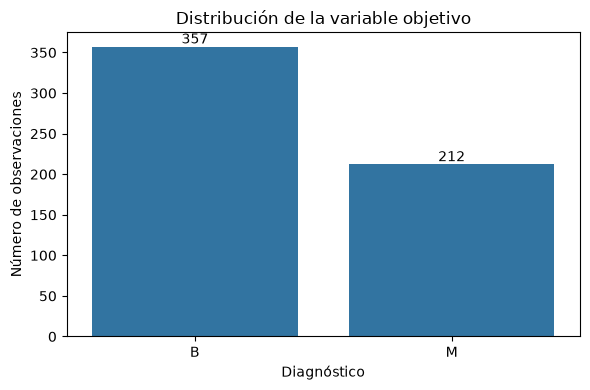

In [9]:
plt.figure(figsize=(6, 4))

ax = sns.countplot(
    data=cancer_df,
    x=TARGET_COLUMN,
    order=["B", "M"]
)

plt.title("Distribución de la variable objetivo")
plt.xlabel("Diagnóstico")
plt.ylabel("Número de observaciones")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

### Interpretación de la variable objetivo

La distribución presenta 357 observaciones benignas, equivalentes al 62.74%, y 212 malignas, equivalentes al 37.26%. Existe una diferencia moderada entre las clases, pero no un desbalance extremo que impida construir el modelo base.

Para conservar esta proporción durante la evaluación, la división entre entrenamiento y prueba se realizará mediante estratificación. Esto permite que ambos conjuntos mantengan una distribución de clases semejante a la del dataset original y evita que la asignación aleatoria produzca una representación inadecuada de la clase maligna.

In [10]:
eda_features = [
    "radius_mean",
    "texture_mean",
    "perimeter_mean",
    "area_mean",
    "concavity_mean",
    "concave points_mean"
]

missing_eda_features = set(eda_features) - set(cancer_df.columns)

if missing_eda_features:
    raise ValueError(
        f"No se encontraron las siguientes variables del EDA: "
        f"{missing_eda_features}"
    )

cancer_df[eda_features].describe().T

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.981,11.70000,13.37000,15.7800,28.1100
texture_mean,569.0,19.289649,4.301036,9.710,16.17000,18.84000,21.8000,39.2800
perimeter_mean,569.0,91.969033,24.298981,43.790,75.17000,86.24000,104.1000,188.5000
area_mean,569.0,654.889104,351.914129,143.500,420.30000,551.10000,782.7000,2501.0000
concavity_mean,569.0,0.088799,0.079720,0.000,0.02956,0.06154,0.1307,0.4268
concave points_mean,569.0,0.048919,0.038803,0.000,0.02031,0.03350,0.0740,0.2012


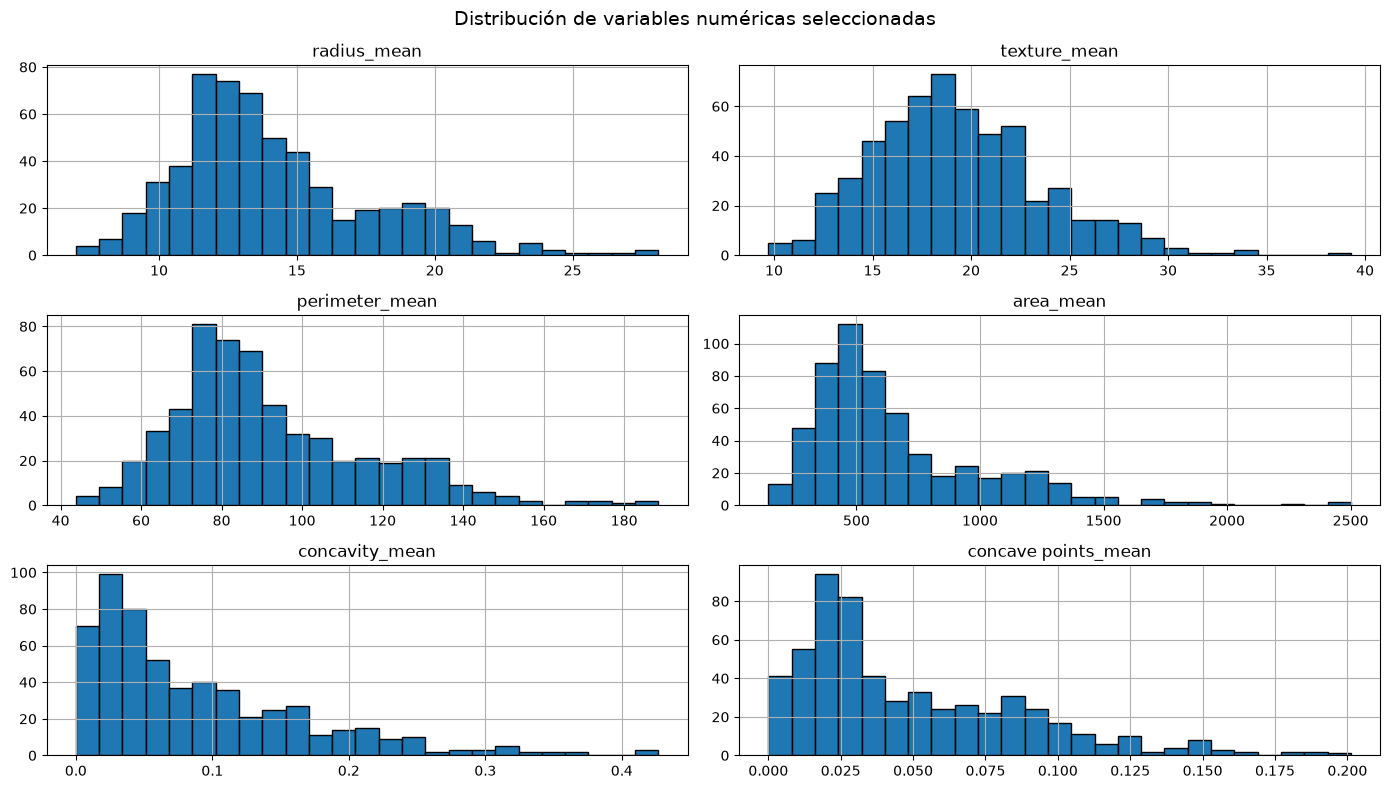

In [11]:
# Histogramas
cancer_df[eda_features].hist(
    figsize=(14, 8),
    bins=25,
    edgecolor="black"
)

plt.suptitle(
    "Distribución de variables numéricas seleccionadas",
    fontsize=14
)
plt.tight_layout()
plt.show()

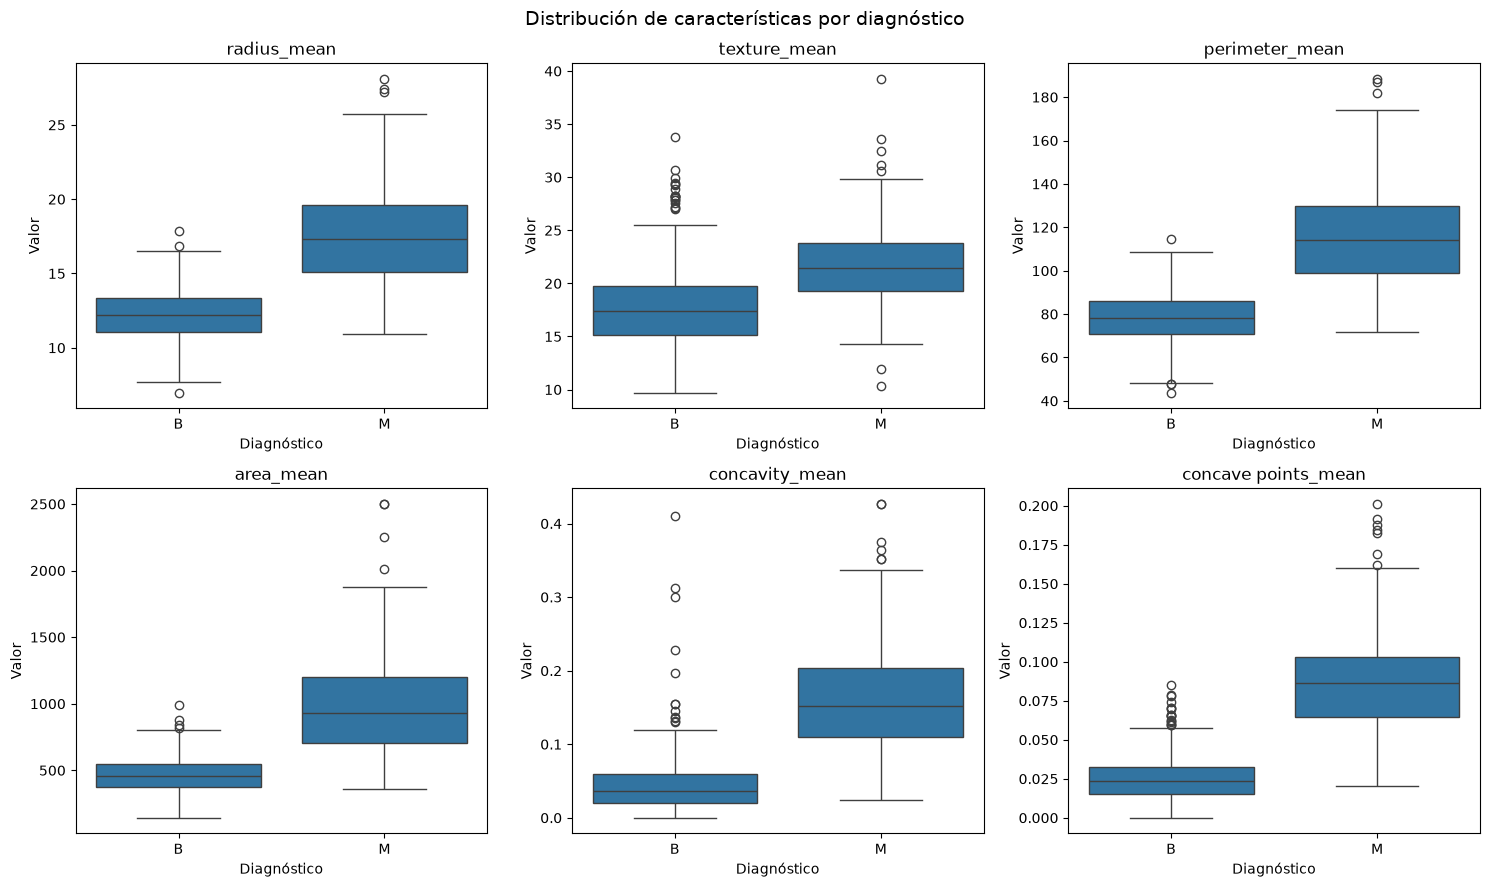

In [12]:
# Boxplots
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for ax, feature in zip(axes, eda_features):
    sns.boxplot(
        data=cancer_df,
        x=TARGET_COLUMN,
        y=feature,
        order=["B", "M"],
        ax=ax
    )

    ax.set_title(feature)
    ax.set_xlabel("Diagnóstico")
    ax.set_ylabel("Valor")

plt.suptitle(
    "Distribución de características por diagnóstico",
    fontsize=14
)
plt.tight_layout()
plt.show()

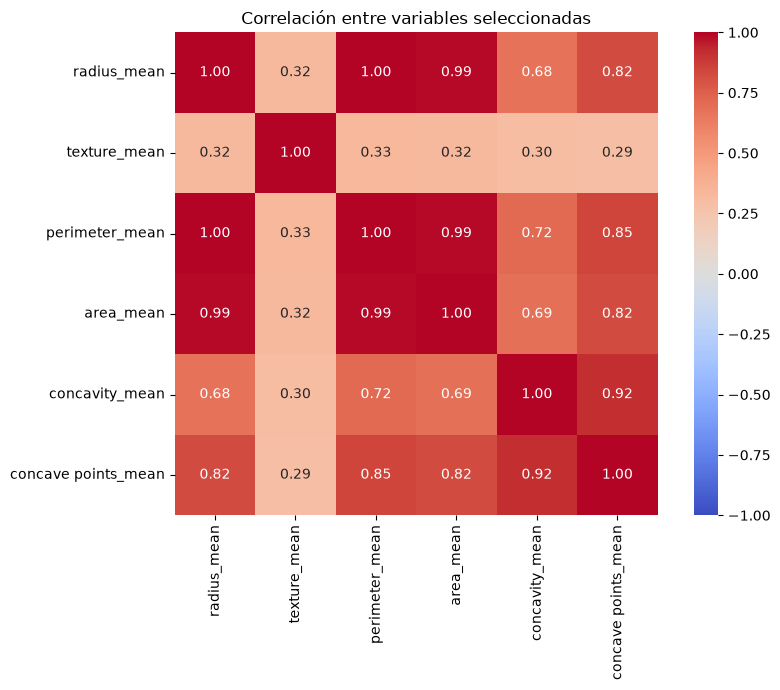

In [13]:
# Matriz de correlación
plt.figure(figsize=(9, 7))

sns.heatmap(
    cancer_df[eda_features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlación entre variables seleccionadas")
plt.tight_layout()
plt.show()

### Hallazgos principales del análisis exploratorio

Las variables relacionadas con radio, perímetro y área presentan escalas diferentes y asociaciones positivas elevadas. Esto es coherente porque describen dimensiones físicas relacionadas del tumor, aunque la correlación no implica causalidad.

Los boxplots muestran diferencias visibles entre las distribuciones de tumores benignos y malignos en variables como `radius_mean`, `perimeter_mean`, `area_mean`, `concavity_mean` y `concave points_mean`. En esta muestra, los tumores malignos tienden a registrar valores superiores en estas características, por lo que podrían aportar información útil para la clasificación.

El criterio IQR identificó 171 registros, equivalentes al 30.05% del dataset, con al menos un valor extremo. Estos registros no se consideran automáticamente errores, pues podrían representar tumores reales con características morfológicas poco frecuentes. Por ello, se conservarán para el entrenamiento del baseline.

## 3. Diagnóstico y limpieza de datos

En esta sección se revisan valores faltantes, duplicados, tipos de datos, categorías inesperadas y observaciones extremas. Cada decisión se documenta para mantener la trazabilidad del proceso.

In [14]:
missing_values = cancer_df.isna().sum()
duplicate_rows = cancer_df.duplicated().sum()

print("Valores faltantes totales:", missing_values.sum())
print("Registros duplicados:", duplicate_rows)

print("\nValores faltantes por columna:")
display(
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
    .to_frame("valores_faltantes")
)

print("\nTipos de datos:")
display(cancer_df.dtypes.to_frame("tipo"))

Valores faltantes totales: 0
Registros duplicados: 0

Valores faltantes por columna:


,valores_faltantes



Tipos de datos:


,tipo
diagnosis,str
radius_mean,float64
texture_mean,float64
perimeter_mean,float64
area_mean,float64
smoothness_mean,float64
compactness_mean,float64
concavity_mean,float64
concave points_mean,float64
symmetry_mean,float64


In [15]:
# Copia de datos originales
df_clean = cancer_df.copy()

duplicates_before = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates()

print(f"Duplicados identificados: {duplicates_before}")
print(f"Duplicados eliminados: {duplicates_before}")
print(f"Dimensiones después de revisar duplicados: {df_clean.shape}")

Duplicados identificados: 0
Duplicados eliminados: 0
Dimensiones después de revisar duplicados: (569, 31)


In [16]:
valid_classes = {"B", "M"}
observed_classes = set(
    df_clean[TARGET_COLUMN].dropna().unique()
)

unexpected_classes = observed_classes - valid_classes

if unexpected_classes:
    raise ValueError(
        f"Se encontraron categorías inesperadas en el objetivo: "
        f"{unexpected_classes}"
    )

predictor_columns = [
    column
    for column in df_clean.columns
    if column != TARGET_COLUMN
]

non_numeric_predictors = (
    df_clean[predictor_columns]
    .select_dtypes(exclude=np.number)
    .columns
    .tolist()
)

print("Clases encontradas:", observed_classes)
print("Predictores con tipo no numérico:", non_numeric_predictors)

assert not non_numeric_predictors, (
    f"Existen predictores no numéricos: {non_numeric_predictors}"
)


Clases encontradas: {'M', 'B'}
Predictores con tipo no numérico: []


In [17]:
# Outliers con IQR
numeric_predictors = (
    df_clean
    .drop(columns=[TARGET_COLUMN])
    .select_dtypes(include=np.number)
    .columns
)

q1 = df_clean[numeric_predictors].quantile(0.25)
q3 = df_clean[numeric_predictors].quantile(0.75)
iqr = q3 - q1

outlier_mask = (
    (df_clean[numeric_predictors] < (q1 - 1.5 * iqr)) |
    (df_clean[numeric_predictors] > (q3 + 1.5 * iqr))
)

outlier_counts = (
    outlier_mask
    .sum()
    .sort_values(ascending=False)
    .to_frame("cantidad_outliers_IQR")
)

display(outlier_counts.head(10))

rows_with_outliers = outlier_mask.any(axis=1).sum()
outlier_percentage = rows_with_outliers / len(df_clean) * 100

print(f"Filas con al menos un outlier: {rows_with_outliers}")
print(f"Porcentaje de filas con outliers: {outlier_percentage:.2f}%")

,cantidad_outliers_IQR
area_se,65
radius_se,38
perimeter_se,38
area_worst,35
smoothness_se,30
fractal_dimension_se,28
compactness_se,28
symmetry_se,27
area_mean,25
fractal_dimension_worst,24


Filas con al menos un outlier: 171
Porcentaje de filas con outliers: 30.05%


### Decisiones de limpieza

1. **Identificador:** la columna `id` se estableció como índice para conservar la trazabilidad, pero no se utilizará como predictor.

2. **Valores faltantes:** no se aplicó imputación porque el diagnóstico de calidad confirmó que el dataset no contiene valores faltantes. En caso de que una versión futura incorpore datos faltantes, la imputación deberá integrarse en el pipeline y ajustarse únicamente con el conjunto de entrenamiento.

3. **Duplicados:** no se identificaron registros duplicados, por lo que no fue necesario eliminar observaciones. Se mantuvo drop_duplicates() como una operación preventiva y reproducible para versiones futuras del dataset.

4. **Tipos de datos:** se comprobó que la variable objetivo contenga solamente las categorías `B` y `M`, y que todos los predictores sean numéricos.

5. **Outliers:** el criterio del rango intercuartílico identificó observaciones extremas en algunas variables. No se eliminaron automáticamente porque pueden corresponder a tumores reales con características morfológicas extremas y no necesariamente a errores de captura. Su eliminación podría descartar información importante para reconocer la clase maligna.

6. **Escalas:** debido a que los predictores se encuentran en escalas diferentes, se utilizará `StandardScaler` dentro del pipeline. De esta manera, el escalador aprenderá sus parámetros solamente con los datos de entrenamiento y se reducirá el riesgo de fuga de información.

## 4. Preparación de los datos

La clase benigna se codifica como `0` y la clase maligna como `1`. Esto permite interpretar el `recall` de la clase positiva como la proporción de tumores malignos que el modelo logra identificar correctamente.

In [18]:
X = df_clean.drop(columns=[TARGET_COLUMN])
y = df_clean[TARGET_COLUMN].map({
    "B": 0,
    "M": 1
})

if y.isna().any():
    raise ValueError(
        "Existen categorías del objetivo que no pudieron codificarse."
    )

print("Dimensiones de los predictores:", X.shape)
print("Dimensiones del objetivo:", y.shape)

print("\nDistribución codificada del objetivo:")
display(y.value_counts().sort_index().to_frame("frecuencia"))

print("\nPrimeros identificadores conservados en el índice:")
display(X.head())

Dimensiones de los predictores: (569, 30)
Dimensiones del objetivo: (569,)

Distribución codificada del objetivo:


,frecuencia
diagnosis,
0,357
1,212



Primeros identificadores conservados en el índice:


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
842302,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
842517,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
84300903,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
84348301,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
84358402,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [19]:
# División train/test 80:20
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Dimensiones de entrenamiento:", X_train.shape)
print("Dimensiones de prueba:", X_test.shape)

class_proportions = pd.DataFrame({
    "dataset_completo": y.value_counts(normalize=True),
    "entrenamiento": y_train.value_counts(normalize=True),
    "prueba": y_test.value_counts(normalize=True)
}).sort_index()

display(class_proportions.round(4))

Dimensiones de entrenamiento: (455, 30)
Dimensiones de prueba: (114, 30)


,dataset_completo,entrenamiento,prueba
diagnosis,,,
0,0.6274,0.6264,0.6316
1,0.3726,0.3736,0.3684


### División de los datos

Se reservó el 20% de las observaciones para evaluar el modelo y se utilizó el 80% restante para el entrenamiento. La división se realizó con `random_state=42` para obtener resultados reproducibles.

El parámetro `stratify=y` conserva aproximadamente la misma proporción de tumores benignos y malignos en los conjuntos de entrenamiento y prueba. El conjunto de prueba permanecerá separado durante el entrenamiento y se utilizará únicamente para la evaluación final del baseline.

## 5. Entrenamiento del modelo base

Se seleccionó una regresión logística porque el problema es de clasificación binaria, su entrenamiento es eficiente y ofrece un punto de partida sencillo e interpretable.

Antes de entrenar el clasificador se aplica estandarización, ya que las variables numéricas se encuentran en escalas diferentes. Ambos pasos se integran en un pipeline para que el escalador aprenda sus parámetros exclusivamente a partir del conjunto de entrenamiento.

In [20]:
baseline_parameters = {
    "test_size": TEST_SIZE,
    "random_state": RANDOM_STATE,
    "max_iter": 1000,
    "solver": "lbfgs",
    "C": 1.0
}

baseline_model = Pipeline(steps=[
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=baseline_parameters["max_iter"],
            solver=baseline_parameters["solver"],
            C=baseline_parameters["C"],
            random_state=baseline_parameters["random_state"]
        )
    )
])

baseline_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`

La regresión logística también permite estimar probabilidades para la clase maligna, lo que facilita calcular ROC AUC y analizar posteriormente distintos umbrales de decisión.

In [21]:
baseline_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['radius_mean','texture_mean','perimeter_mean',...,'concave points_worst', 'symmetry_worst','fractal_dimension_worst']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [22]:
y_pred = baseline_model.predict(X_test)
y_proba = baseline_model.predict_proba(X_test)[:, 1]

baseline_metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(
        y_test,
        y_pred,
        zero_division=0
    ),
    "recall": recall_score(
        y_test,
        y_pred,
        zero_division=0
    ),
    "f1_score": f1_score(
        y_test,
        y_pred,
        zero_division=0
    ),
    "roc_auc": roc_auc_score(y_test, y_proba)
}

metrics_df = (
    pd.Series(baseline_metrics, name="valor")
    .to_frame()
    .round(4)
)

display(metrics_df)

,valor
accuracy,0.9649
precision,0.9750
recall,0.9286
f1_score,0.9512
roc_auc,0.9960


In [23]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Benigno", "Maligno"],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

     Benigno     0.9595    0.9861    0.9726        72
     Maligno     0.9750    0.9286    0.9512        42

    accuracy                         0.9649       114
   macro avg     0.9672    0.9573    0.9619       114
weighted avg     0.9652    0.9649    0.9647       114



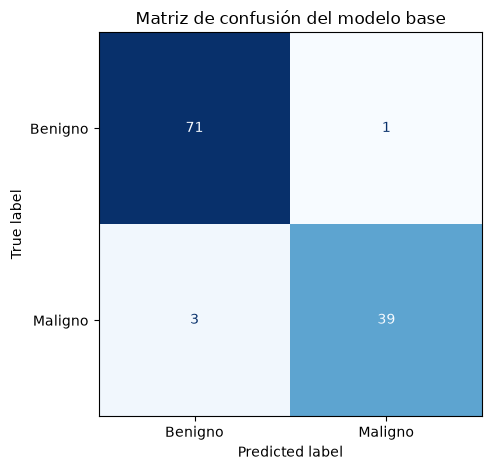

In [24]:
# Matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Benigno", "Maligno"],
    cmap="Blues",
    colorbar=False
)

plt.title("Matriz de confusión del modelo base")
plt.tight_layout()
plt.show()

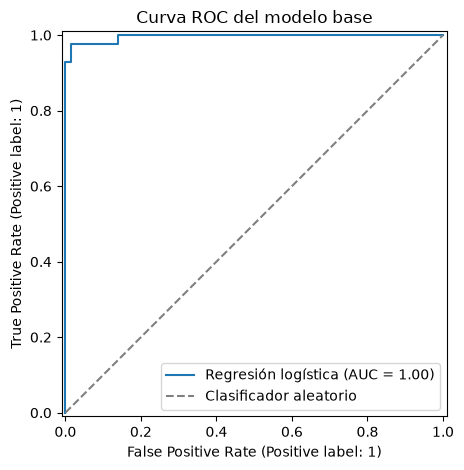

In [25]:
# Curva ROC
RocCurveDisplay.from_predictions(
    y_test,
    y_proba,
    name="Regresión logística"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Clasificador aleatorio"
)

plt.title("Curva ROC del modelo base")
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
# Predicciones
prediction_results = pd.DataFrame(
    {
        "diagnostico_real": y_test.map({
            0: "Benigno",
            1: "Maligno"
        }),
        "diagnostico_predicho": pd.Series(
            y_pred,
            index=y_test.index
        ).map({
            0: "Benigno",
            1: "Maligno"
        }),
        "probabilidad_maligno": y_proba
    },
    index=y_test.index
)

prediction_results.index.name = ID_COLUMN

display(prediction_results.head(10))

,diagnostico_real,diagnostico_predicho,probabilidad_maligno
id,,,
865137,Benigno,Benigno,0.000365
884948,Maligno,Maligno,1.000000
901303,Benigno,Benigno,0.042568
862548,Maligno,Maligno,0.576187
9112085,Benigno,Maligno,0.509155
894329,Benigno,Benigno,0.000616
855138,Maligno,Maligno,0.761534
9012568,Benigno,Benigno,0.001012
862485,Benigno,Benigno,0.000569


In [27]:
accuracy_value = baseline_metrics["accuracy"]
precision_value = baseline_metrics["precision"]
recall_value = baseline_metrics["recall"]
f1_value = baseline_metrics["f1_score"]
roc_auc_value = baseline_metrics["roc_auc"]

print(
    f"Accuracy: el modelo clasificó correctamente "
    f"aproximadamente el {accuracy_value:.2%} de las observaciones."
)

print(
    f"Recall: identificó correctamente el "
    f"{recall_value:.2%} de los tumores malignos."
)

print(
    f"Precision: el {precision_value:.2%} de los casos "
    f"predichos como malignos realmente fueron malignos."
)

print(
    f"F1-score: el equilibrio entre precision y recall fue "
    f"{f1_value:.4f}."
)

print(
    f"ROC AUC: la capacidad general de discriminación fue "
    f"{roc_auc_value:.4f}."
)

Accuracy: el modelo clasificó correctamente aproximadamente el 96.49% de las observaciones.
Recall: identificó correctamente el 92.86% de los tumores malignos.
Precision: el 97.50% de los casos predichos como malignos realmente fueron malignos.
F1-score: el equilibrio entre precision y recall fue 0.9512.
ROC AUC: la capacidad general de discriminación fue 0.9960.


### Interpretación de los resultados

El modelo base obtuvo un `accuracy` de **0.9649**, lo que significa que clasificó correctamente **110 de las 114 observaciones del conjunto de prueba**, equivalentes al **96.49%**. La matriz de confusión muestra que se identificaron correctamente 71 tumores benignos y 39 tumores malignos, mientras que se produjo un falso positivo y tres falsos negativos.

El `recall` para la clase maligna fue de **0.9286**, por lo que el modelo identificó correctamente **39 de los 42 tumores realmente malignos**, equivalentes al **92.86%**. Sin embargo, tres tumores malignos fueron clasificados como benignos. Este resultado requiere especial atención porque, en un problema de apoyo al diagnóstico, los falsos negativos podrían representar casos que no recibirían una revisión oportuna. Por esta razón, el recall de la clase maligna es una de las métricas más relevantes para interpretar el baseline.

La `precision` fue de **0.9750**, lo que indica que **39 de las 40 observaciones clasificadas como malignas realmente pertenecían a esa clase**. El `F1-score` de **0.9512** muestra un equilibrio alto entre precision y recall. Por su parte, el ROC AUC de **0.9960** indica una capacidad excelente para separar ambas clases a través de diferentes umbrales de decisión. Este valor no significa que el modelo acierte el 99.60% de los diagnósticos, sino que presenta una alta capacidad de discriminación entre tumores benignos y malignos.

En conjunto, los resultados son excelentes para un modelo base en esta partición de prueba. No obstante, deben considerarse preliminares porque proceden de una sola división de 114 observaciones. Antes de considerar una aplicación real sería necesario comprobar la estabilidad mediante validación cruzada, analizar la sensibilidad a diferentes particiones, evaluar otros umbrales de decisión y validar el modelo con datos externos.

# 6. Registro del experimento en MLflow

El experimento del modelo base se registrará mediante MLflow Tracking para conservar sus parámetros, métricas y artefactos. El pipeline incluye tanto la estandarización como el clasificador, lo que permite conservar el flujo completo del modelo base como artefacto reproducible.

In [29]:
import mlflow
import mlflow.sklearn

MLFLOW_TRACKING_URI = "sqlite:///mlflow.db"
EXPERIMENT_NAME = "TC5061_Breast_Cancer_Baseline"

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow:", mlflow.__version__)
print("Tracking URI:", mlflow.get_tracking_uri())
print("Experimento:", EXPERIMENT_NAME)

2026/10/02 21:52:47 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/02 21:52:47 INFO mlflow.store.db.utils: Updating database tables
2026/10/02 21:52:48 INFO mlflow.tracking.fluent: Experiment with name 'TC5061_Breast_Cancer_Baseline' does not exist. Creating a new experiment.


MLflow: 3.16.1
Tracking URI: sqlite:///mlflow.db
Experimento: TC5061_Breast_Cancer_Baseline


In [30]:
from mlflow.models import infer_signature

input_example = X_train.head(5).copy()

model_signature = infer_signature(
    X_train,
    baseline_model.predict(X_train)
)

print("Firma del modelo preparada correctamente.")
display(input_example)

Firma del modelo preparada correctamente.


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
845636,16.02,23.24,102.70,797.8,0.08206,0.06669,0.03299,0.03323,0.1528,0.05697,0.3795,1.1870,2.466,40.51,0.004029,0.009269,0.01101,0.007591,0.01460,0.003042,19.19,33.88,123.80,1150.0,0.11810,0.1551,0.1459,0.09975,0.2948,0.08452
87139402,12.32,12.39,78.85,464.1,0.10280,0.06981,0.03987,0.03700,0.1959,0.05955,0.2360,0.6656,1.670,17.43,0.008045,0.011800,0.01683,0.012410,0.01924,0.002248,13.50,15.64,86.97,549.1,0.13850,0.1266,0.1242,0.09391,0.2827,0.06771
905190,12.85,21.37,82.63,514.5,0.07551,0.08316,0.06126,0.01867,0.1580,0.06114,0.4993,1.7980,2.552,41.24,0.006011,0.044800,0.05175,0.013410,0.02669,0.007731,14.40,27.01,91.63,645.8,0.09402,0.1936,0.1838,0.05601,0.2488,0.08151
907914,14.90,22.53,102.10,685.0,0.09947,0.22250,0.27330,0.09711,0.2041,0.06898,0.2530,0.8749,3.466,24.19,0.006965,0.062130,0.07926,0.022340,0.01499,0.005784,16.35,27.57,125.40,832.7,0.14190,0.7090,0.9019,0.24750,0.2866,0.11550
852781,18.61,20.25,122.10,1094.0,0.09440,0.10660,0.14900,0.07731,0.1697,0.05699,0.8529,1.8490,5.632,93.54,0.010750,0.027220,0.05081,0.019110,0.02293,0.004217,21.31,27.26,139.90,1403.0,0.13380,0.2117,0.3446,0.14900,0.2341,0.07421


In [31]:
run_parameters = {
    "model_type": "LogisticRegression",
    "scaler": "StandardScaler",
    "test_size": TEST_SIZE,
    "random_state": RANDOM_STATE,
    "max_iter": baseline_parameters["max_iter"],
    "solver": baseline_parameters["solver"],
    "C": baseline_parameters["C"],
    "n_train_rows": X_train.shape[0],
    "n_test_rows": X_test.shape[0],
    "n_features": X_train.shape[1]
}

display(
    pd.Series(
        run_parameters,
        name="valor"
    ).to_frame()
)

,valor
model_type,LogisticRegression
scaler,StandardScaler
test_size,0.2
random_state,42
max_iter,1000
solver,lbfgs
C,1.0
n_train_rows,455
n_test_rows,114
n_features,30


In [32]:
with mlflow.start_run(
    run_name="logistic_regression_baseline"
) as run:

    # Registrar parámetros
    mlflow.log_params(run_parameters)

    # Registrar métricas
    mlflow.log_metrics(baseline_metrics)

    # Agregar etiquetas descriptivas
    mlflow.set_tags({
        "course": "TC5061",
        "student": "Daniel Ruan Aguilar",
        "dataset": "Breast Cancer Wisconsin Diagnostic",
        "task": "binary_classification",
        "stage": "baseline"
    })

    # Registrar el pipeline entrenado
    mlflow.sklearn.log_model(
        sk_model=baseline_model,
        name="baseline_model",
        signature=model_signature,
        input_example=input_example
    )

    RUN_ID = run.info.run_id
    EXPERIMENT_ID = run.info.experiment_id

print("Experimento registrado correctamente.")
print("Experiment ID:", EXPERIMENT_ID)
print("Run ID:", RUN_ID)

Experimento registrado correctamente.
Experiment ID: 1
Run ID: 241d4ddbf8864eceae04b2834d2518fa


In [33]:
logged_run = mlflow.get_run(RUN_ID)

print("Estado:", logged_run.info.status)
print(
    "Nombre del run:",
    logged_run.data.tags.get("mlflow.runName")
)

print("\nParámetros registrados:")
display(
    pd.Series(
        logged_run.data.params,
        name="valor"
    ).to_frame()
)

print("\nMétricas registradas:")
display(
    pd.Series(
        logged_run.data.metrics,
        name="valor"
    ).to_frame().round(4)
)

Estado: FINISHED
Nombre del run: logistic_regression_baseline

Parámetros registrados:


,valor
model_type,LogisticRegression
scaler,StandardScaler
test_size,0.2
random_state,42
max_iter,1000
solver,lbfgs
C,1.0
n_train_rows,455
n_test_rows,114
n_features,30



Métricas registradas:


,valor
accuracy,0.9649
precision,0.9750
recall,0.9286
f1_score,0.9512
roc_auc,0.9960


In [34]:
assert logged_run.info.status == "FINISHED"

assert set(run_parameters).issubset(
    logged_run.data.params.keys()
)

assert set(baseline_metrics).issubset(
    logged_run.data.metrics.keys()
)

print("Registro de MLflow validado correctamente.")
print("Run ID:", RUN_ID)

Registro de MLflow validado correctamente.
Run ID: 241d4ddbf8864eceae04b2834d2518fa


### Evidencia del experimento registrado
 
Las siguientes capturas muestran el experimento `TC5061_Breast_Cancer_Baseline` y el run `logistic_regression_baseline` en la interfaz de MLflow. Se observa que el run finalizó correctamente y que contiene los parámetros, las métricas y el pipeline del modelo base como artefacto.

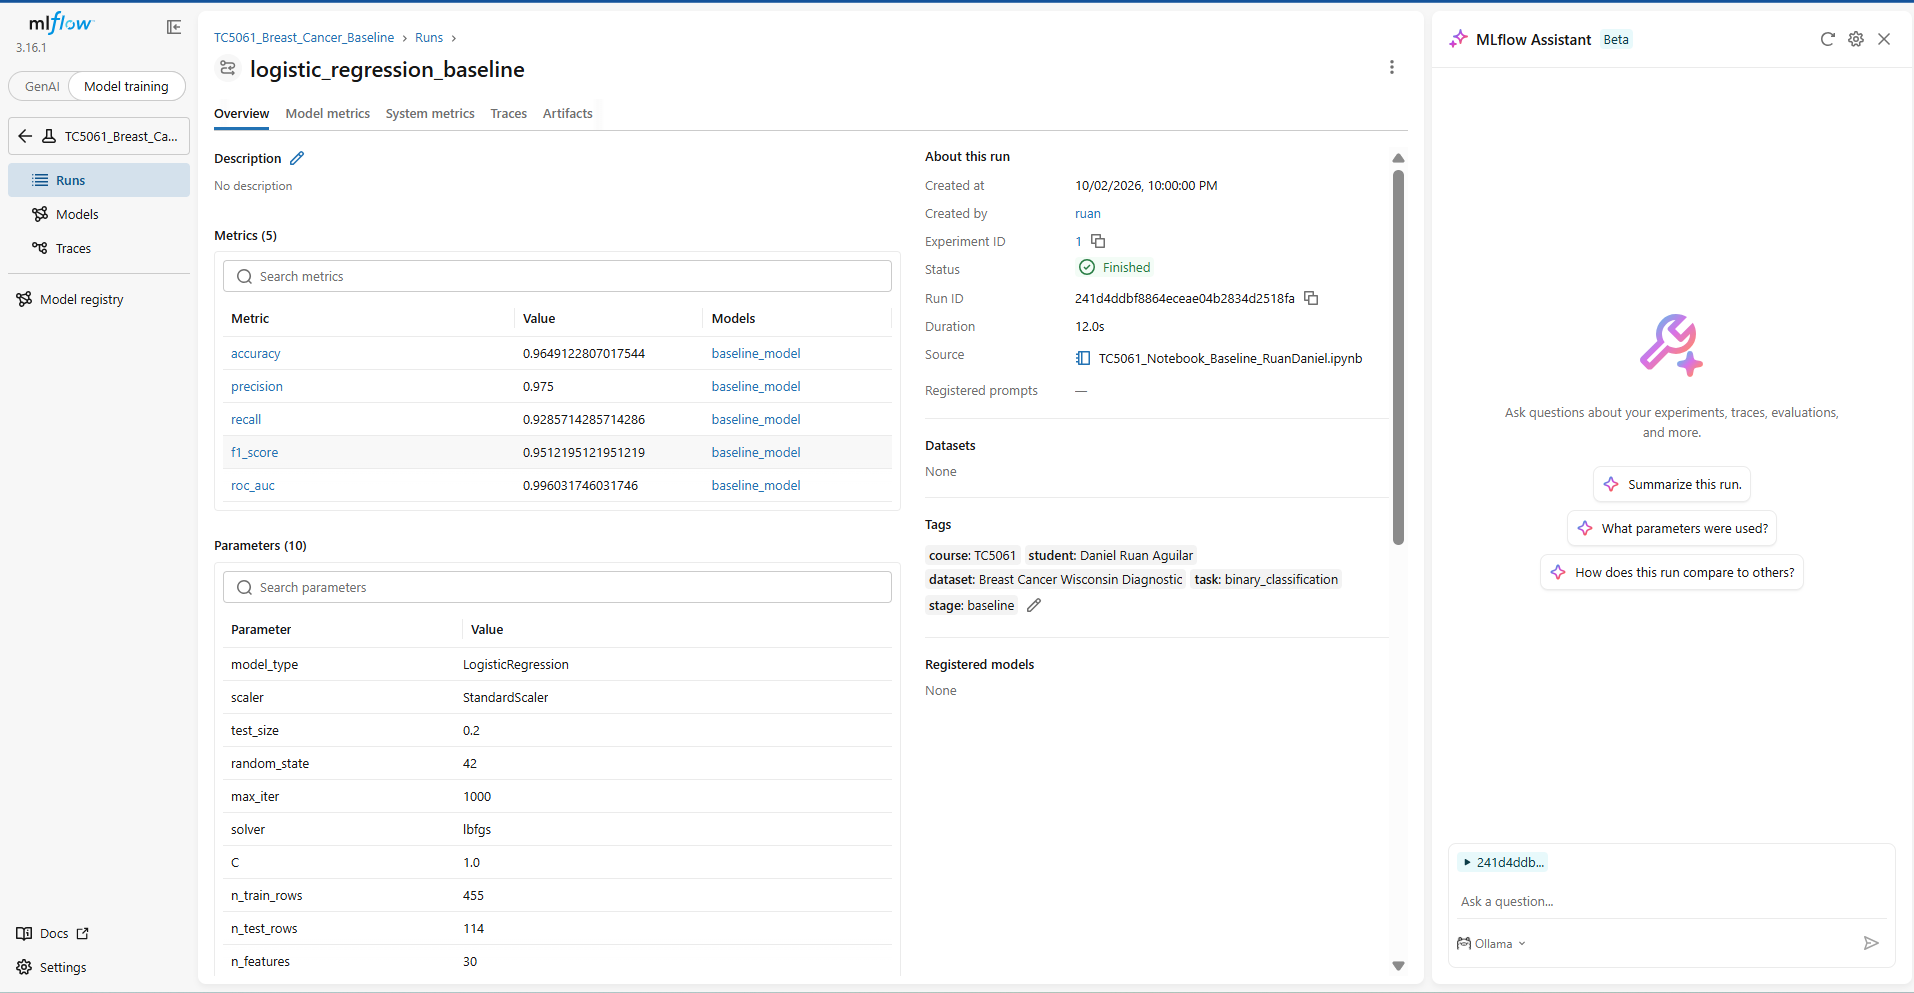

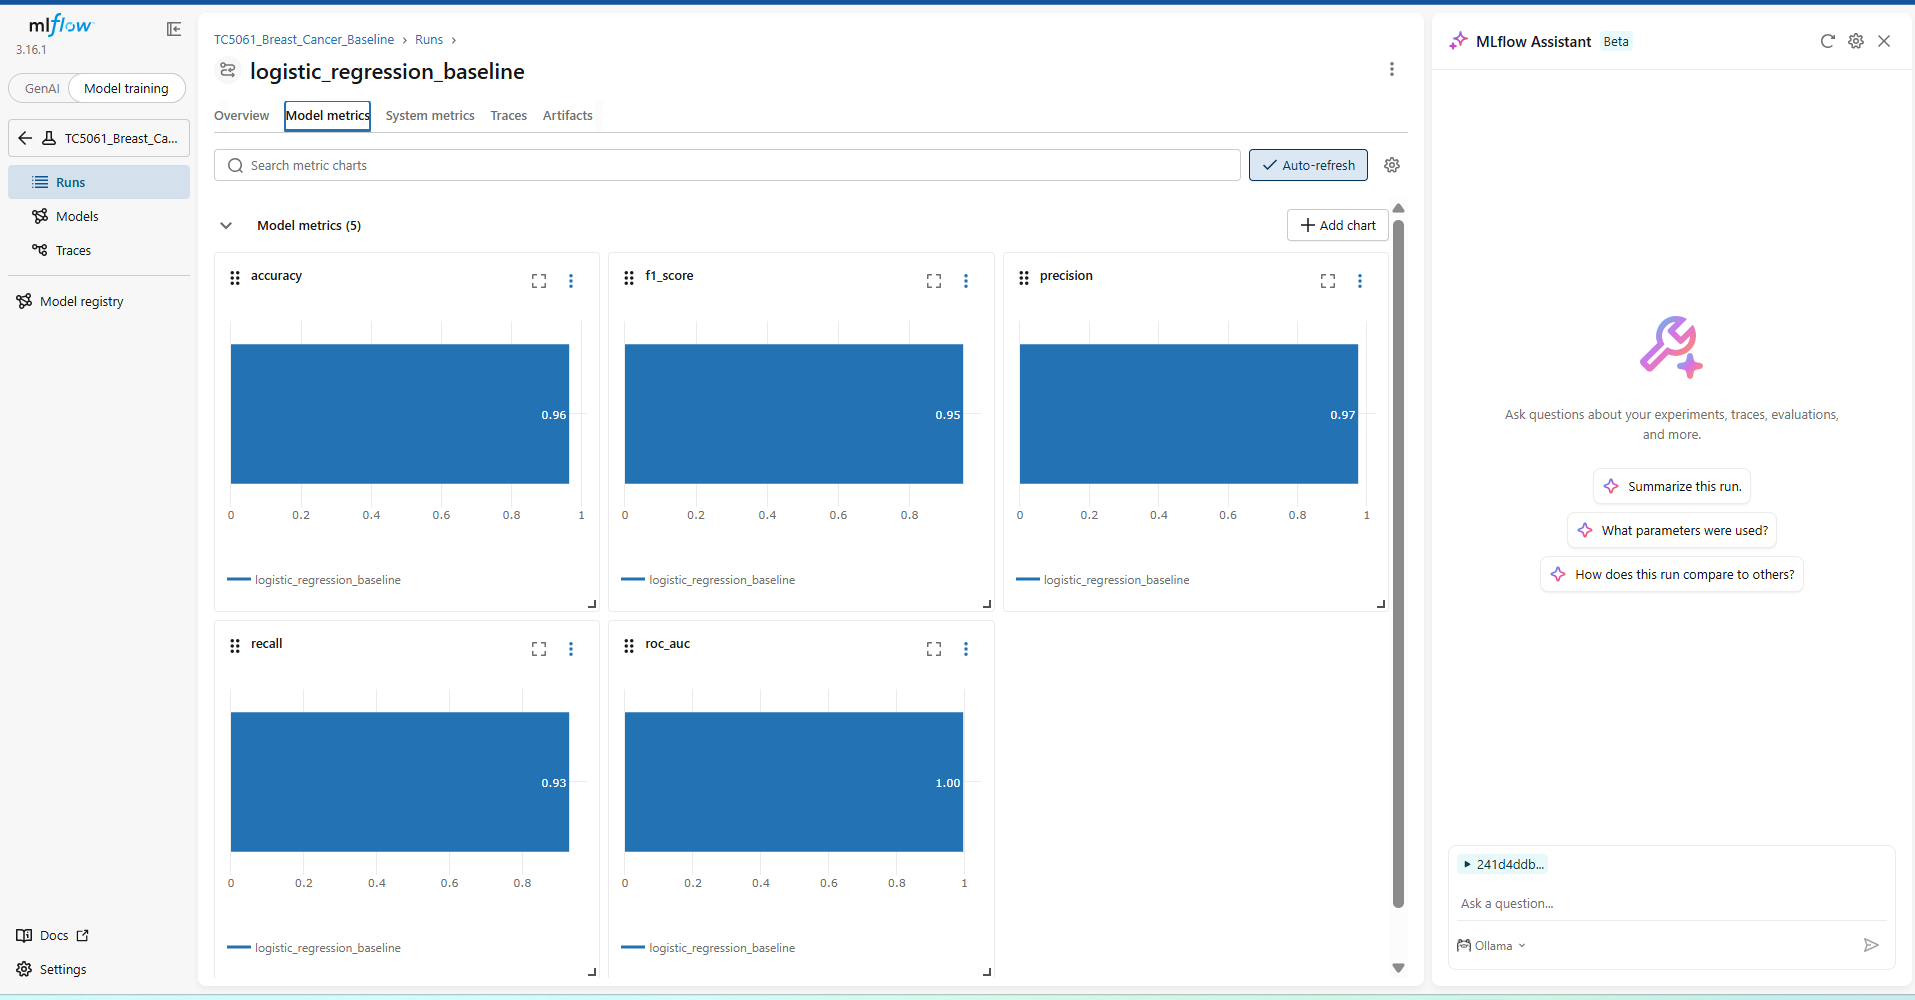

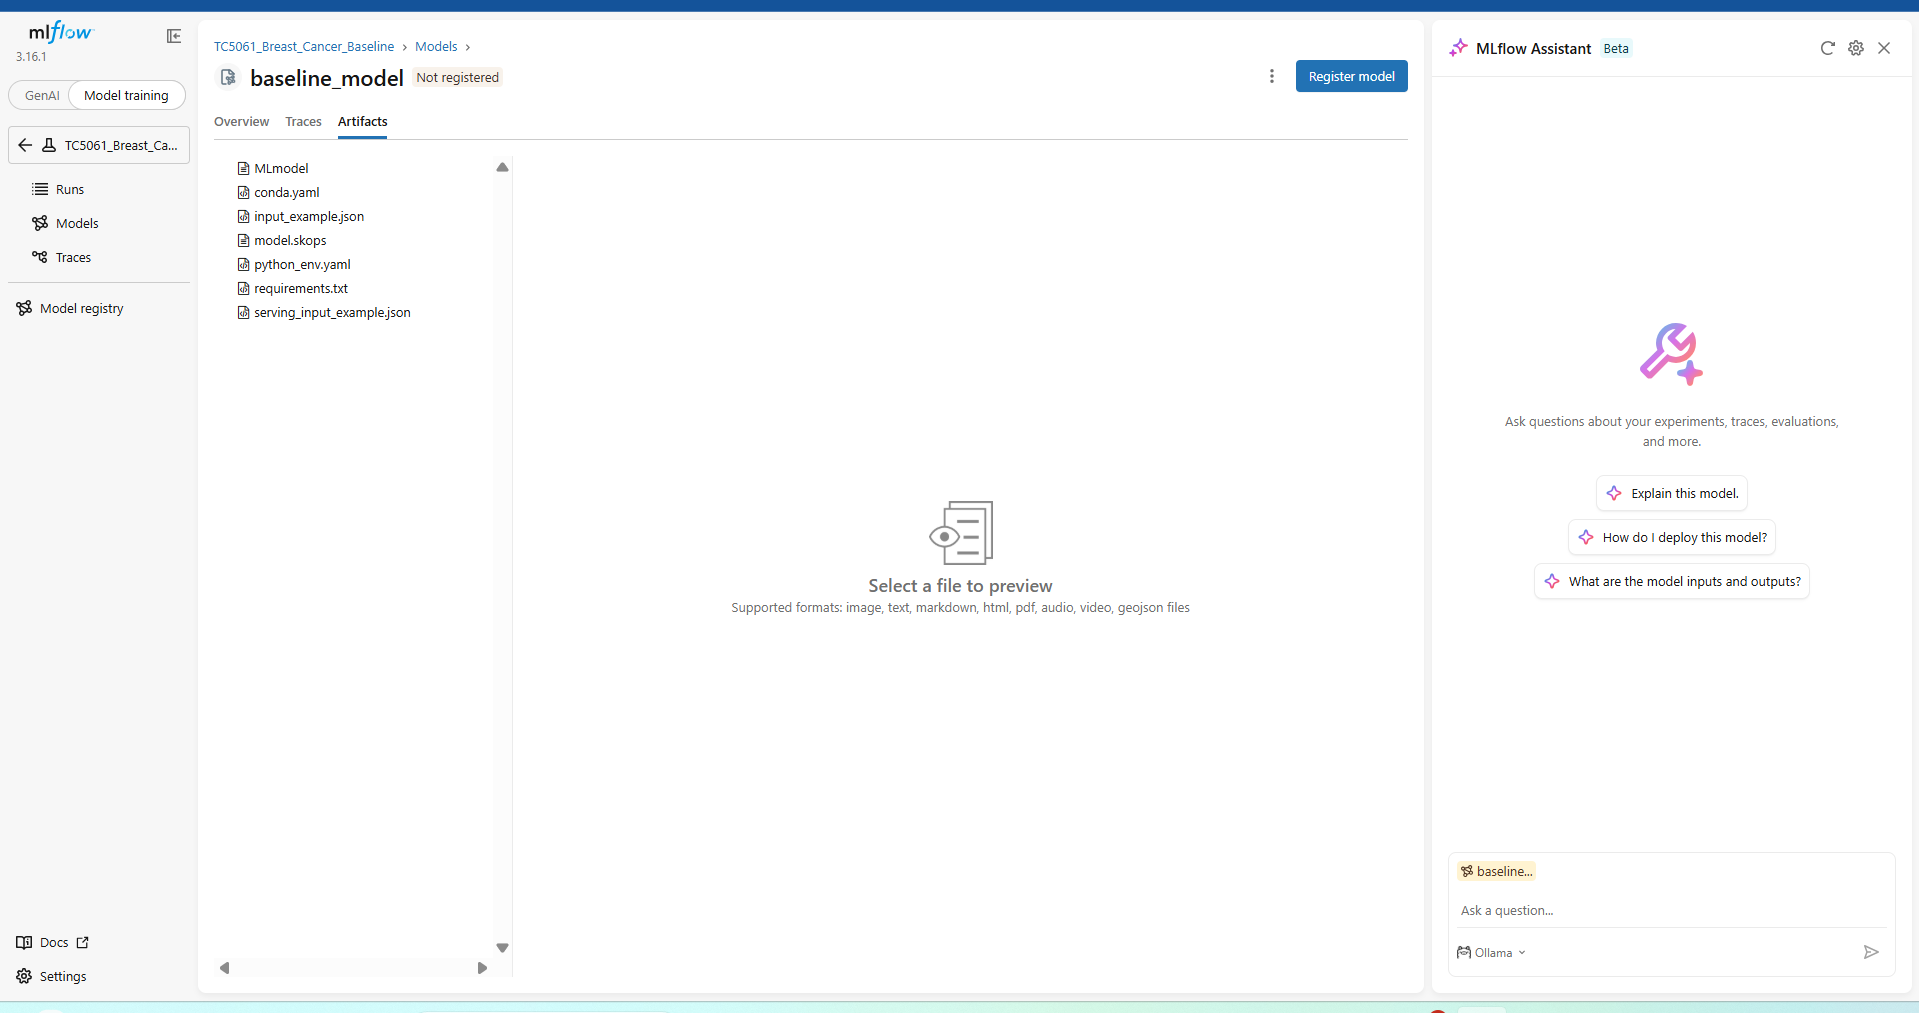

In [35]:
from IPython.display import Image, display

display(
    Image(
        filename="resumen_run.png",
        width=1200
    )
)

display(
    Image(
        filename="metricas.png",
        width=1200
    )
)
display(
    Image(
        filename="artefactos.png",
        width=1200
    )
)

## 7. Reflexión final sobre MLOps

El desarrollo de este modelo base permitió recorrer un flujo completo de Machine Learning, desde la descripción y limpieza de los datos hasta el entrenamiento, la evaluación y el registro del experimento. Una de las principales conclusiones es que una métrica alta no debe interpretarse de manera aislada. Aunque el modelo alcanzó un accuracy de 96.49%, fue necesario analizar la matriz de confusión, el recall, la precision, el F1-score y el ROC AUC para comprender mejor sus fortalezas y limitaciones.

En medicina, un falso negativo, es decir, un tumor maligno clasificado como benigno, es más grave que un falso positivo, porque implica no detectar un caso que requiere revisión y atención médica. Por ello, en este caso la prioridad debe ser mejorar el recall. Considero que, dentro de un sistema de apoyo y siempre con supervisión profesional, es preferible revisar casos adicionales derivados de falsos positivos que dejar pasar un tumor maligno. El baseline obtuvo un recall de 92.86%, pero produjo tres falsos negativos, por lo que todavía existe margen de mejora. En experimentos posteriores evaluaría distintos umbrales de clasificación, validación cruzada, balanceo de clases y otros modelos, procurando aumentar el recall sin reducir excesivamente la precision.

Desde la perspectiva de MLOps, mejoraría este flujo mediante el versionamiento del código, los datos, las dependencias y los modelos. También incorporaría pruebas automáticas para validar el esquema del dataset, detectar cambios en las distribuciones, comprobar la reproducibilidad de las métricas y evitar que datos de prueba se utilicen durante el entrenamiento. MLflow facilita esta trazabilidad al conservar parámetros, métricas y artefactos de cada ejecución. Como siguiente etapa, los modelos candidatos podrían incorporarse al Model Registry para administrar versiones y establecer criterios de aprobación antes de su uso.

Estos aprendizajes se relacionan directamente con mi trabajo como Software Test Engineer, donde participo en el desarrollo y validación de páginas administrativas, pruebas automatizadas y asistentes virtuales para clientes. En ese contexto, un modelo o asistente no debe evaluarse únicamente porque funciona en una demostración. Es necesario definir casos de prueba, resultados esperados, métricas, criterios de aceptación y mecanismos de regresión. La trazabilidad de MLflow es comparable con conservar evidencias de ejecución, configuraciones y resultados de pruebas. Aplicar estas prácticas permitiría detectar degradaciones, comparar versiones de asistentes virtuales y asegurar que los cambios en una página administrativa o servicio inteligente no afecten funciones previamente validadas.